## POLARITY WITH CNN

* Import and load Variable

In [1]:
import tensorflow
import numpy as np
from tensorflow.keras import layers, models
from obspy import UTCDateTime, read
import obspy
import os
from tqdm import tqdm
import pandas as pd
import pickle
# Load the data
p_time_list = pd.read_csv("p_time20082024.csv", sep=";")

def load_var(model_name:str):
    model_path = f'./var/{model_name}'
    if os.path.exists(model_path):
        with open(model_path, 'rb') as file:
            loaded_model = pickle.load(file)
            print(f"Model '{model_name}' loaded successfully.")
            return loaded_model
    else:
        print(f"Model '{model_name}' does not exist.")


# Training Data
X_train = load_var("X_train.pkl")
Y_train = load_var("Y_train.pkl")
print(X_train.shape, Y_train.shape)
print(X_train.dtype, Y_train.dtype)

# Validation Data
X_validation = load_var("X_validation.pkl")
Y_validation = load_var("Y_validation.pkl")
print(X_validation.shape, Y_validation.shape)
print(X_validation.dtype, Y_validation.dtype)

# Test Data
X_test = load_var("X_test.pkl")
Y_test = load_var("Y_test.pkl")
print(X_test.shape, Y_test.shape)
print(X_test.dtype, Y_test.dtype)


print([np.isnan(X_train).any(), 
       np.isnan(Y_train).any(), 
       np.isnan(X_validation).any(), 
       np.isnan(Y_validation).any(), 
       np.isnan(X_test).any(), 
       np.isnan(Y_test).any()]
      )  # Check for NaNs in all variables
print([np.isinf(X_train).any(), 
       np.isinf(Y_train).any(), 
       np.isinf(X_validation).any(), 
       np.isinf(Y_validation).any(), 
       np.isinf(X_test).any(), 
       np.isinf(Y_test).any()]
      )  # Check for infinite values in all variables

Model 'X_train.pkl' loaded successfully.
Model 'Y_train.pkl' loaded successfully.
(31482, 26) (31482,)
float64 int32
Model 'X_validation.pkl' loaded successfully.
Model 'Y_validation.pkl' loaded successfully.
(6759, 26) (6759,)
float64 int32
Model 'X_test.pkl' loaded successfully.
Model 'Y_test.pkl' loaded successfully.
(6726, 26) (6726,)
float64 int32
[False, False, False, False, False, False]
[False, False, False, False, False, False]


* Clean the data if its needed

In [2]:
def cleaning(data_1:np,data_2:np):
    valid_indices = ~np.isnan(data_1).any(axis=1)  # Keep rows that do not have NaN in X_train
    data_1_clean = data_1[valid_indices]
    data_2_clean = data_2[valid_indices]
    return data_1_clean, data_2_clean
# example Filter X_test, Y_test
X_test, Y_test = cleaning(X_test,Y_test)

* CNN MODEL
Membuat arsitektur model

In [2]:
def create_cnn_model_1(input_shape):
    """
    Create a 1D CNN model for first-motion polarity classification.
    Args:
        input_shape (tuple): Shape of the input data (e.g., (1000, 1)).
    Returns:
        keras.Model: Compiled CNN model.
    """
    model = models.Sequential()

    # 1D Convolutional Layers
    model.add(layers.Conv1D(32, 3, activation='relu', input_shape=input_shape))
    model.add(layers.MaxPooling1D(2))
    
    model.add(layers.Conv1D(64, 3, activation='relu'))
    model.add(layers.MaxPooling1D(2))
    
    model.add(layers.Conv1D(128, 3, activation='relu'))
    model.add(layers.MaxPooling1D(2))

    # Flatten the data for the Dense layers
    model.add(layers.Flatten())
    model.add(layers.Dense(128, activation='relu'))
    model.add(layers.Dense(1, activation='sigmoid'))  # Binary classification (compressional or dilatational)

    # Compile the model
    model.compile(optimizer='adam',
                loss='binary_crossentropy',
                metrics=['accuracy'])

    return model

def create_cnn_model_2(input_shape):
    """
    Create a deeper 1D CNN model for first-motion polarity classification.
    Args:
        input_shape (tuple): Shape of the input data (e.g., (1000, 1)).
    Returns:
        keras.Model: Compiled CNN model.
    """
    model = models.Sequential()

    # 1D Convolutional Layers
    model.add(layers.Conv1D(32, 3, activation='relu', padding='same', input_shape=input_shape))
    model.add(layers.MaxPooling1D(2))
    
    model.add(layers.Conv1D(64, 3, activation='relu', padding='same'))
    model.add(layers.MaxPooling1D(2))
    
    model.add(layers.Conv1D(128, 3, activation='relu', padding='same'))
    model.add(layers.MaxPooling1D(2))

    # Additional convolutional layers for a deeper network
    model.add(layers.Conv1D(256, 3, activation='relu', padding='same'))
    model.add(layers.MaxPooling1D(2))
    
    model.add(layers.Conv1D(512, 3, activation='relu', padding='same'))
    model.add(layers.GlobalMaxPooling1D())

    # Flatten the data for the Dense layers
    model.add(layers.Flatten())
    
    # Additional dense layers
    model.add(layers.Dense(256, activation='relu'))
    model.add(layers.Dropout(0.5))  # Dropout to reduce overfitting
    
    model.add(layers.Dense(128, activation='relu'))
    model.add(layers.Dropout(0.5))
    
    model.add(layers.Dense(1, activation='sigmoid'))  # Binary classification

    # Compile the model
    model.compile(optimizer='adam',
                  loss='binary_crossentropy',
                  metrics=['accuracy'])

    return model


Training Model CNN menggunakan data test, jumlah epoch, batch size dan validation split di variasikan

In [5]:
input_shape = (X_train.shape[1], 1)  # Length of waveform, 1 channel
model_1 = create_cnn_model_1(input_shape)
model_2 = create_cnn_model_2(input_shape)
model_3 = create_cnn_model_2(input_shape)

model_1.summary()

Model: "sequential_6"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d_26 (Conv1D)              │ (None, 24, 32)         │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_22 (MaxPooling1D) │ (None, 12, 32)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_27 (Conv1D)              │ (None, 10, 64)         │         6,208 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_23 (MaxPooling1D) │ (None, 5, 64)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_28 (Conv1D)              │ (None, 3, 128)         │        24,704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_24 (MaxPooling1D) │ (None, 1, 128)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_6 (Flatten)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_16 (Dense)                │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_17 (Dense)                │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 47,681 (186.25 KB)

 Trainable params: 47,681 (186.25 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# Create the model
input_shape = (X_train.shape[1], 1)  # Length of waveform, 1 channel
model_1 = create_cnn_model_1(input_shape)
model_2 = create_cnn_model_2(input_shape)
model_3 = create_cnn_model_2(input_shape)

# Train the model
model_1.fit(X_train, Y_train, epochs=10, batch_size=2, validation_split=0.1)
model_2.fit(X_train, Y_train, epochs=10, batch_size=2, validation_split=0.3)
model_3.fit(X_train, Y_train, epochs=10, batch_size=2, validation_split=0.1)

* Save the model
Simpan model ke dalam format pkl untuk dipanggil kemudian

In [7]:
pickle.dump(model_1,open("model/polarity_1_3LF2D.pkl", "wb"))
pickle.dump(model_2,open("model/polarity_2_5LF3D.pkl", "wb"))
pickle.dump(model_3,open("model/polarity_3_5LF3D.pkl", "wb"))

## Directly Load the saved Model

In [8]:
import os
def load_model(model_name:str):
    """
    Load model yang sudah tersimpan.
    """
    model_path = f'./model/{model_name}'
    if os.path.exists(model_path):
        with open(model_path, 'rb') as file:
            loaded_model = pickle.load(file)
            print(f"Model '{model_name}' loaded successfully.")
            return loaded_model
    else:
        print(f"Model '{model_name}' does not exist.")

model_1 =load_model("polarity_1_3LF2D.pkl")
model_2 =load_model("polarity_2_5LF3D.pkl")
model_3 =load_model("polarity_3_5LF3D.pkl")

Model 'polarity_1_3LF2D.pkl' loaded successfully.
Model 'polarity_2_5LF3D.pkl' loaded successfully.
Model 'polarity_3_5LF3D.pkl' loaded successfully.


In [9]:
from tensorflow.keras.utils import plot_model

plot_model(model_1, to_file='Model_1.png', show_shapes=True, show_layer_names=True)
plot_model(model_2, to_file='Model_2.png', show_shapes=True, show_layer_names=True)
plot_model(model_3, to_file='Model_3.png', show_shapes=True, show_layer_names=True)
print("model saved")

model saved


Definisi Fungsi, Side Layer(Probabilitas Prediksi Ke Polarity), Perhitungan Performa, Plot Confusion Matriks dan Grafik performa

In [10]:
import numpy as np
import seaborn as sns
import matplotlib.ticker as mtick
import matplotlib.pyplot as plt
from scipy import stats

def probabilityToPolarity(probability_value, threshold=0.5):
    """
    Mengubah nilai probabilitas hasil prediksi menjadi nilai polarity
    """
    polarity = (probability_value >= threshold).astype(int)
    return polarity

def getConfusionMatriks(prediction_label, true_label):
    """
    Melakukan perhitungan performa hasil prediksi dengan nilai yang sebenarnya
    """
    TP = FP = TN = FN = 0
    prediction_label = probabilityToPolarity(prediction_label)
    for true_label, pred_label in zip(true_label, prediction_label):
        # print(true_label, pred_label)
        if true_label == 1 and pred_label == 1:
            TP += 1  # True Positive
        elif true_label == 0 and pred_label == 1:
            FP += 1  # False Positive
        elif true_label == 0 and pred_label == 0:
            TN += 1  # True Negative
        elif true_label == 1 and pred_label == 0:
            FN += 1  # False Negative
    # Calculate Accuracy
    accuracy = (TP + TN) / (TP + TN + FP + FN)
    # Calculate Precision (handling division by zero)
    precision = TP / (TP + FP) if (TP + FP) > 0 else 0
    # Calculate Recall (handling division by zero)
    recall = TP / (TP + FN) if (TP + FN) > 0 else 0
    # Calculate F1-Score (handling division by zero)
    f1_score = 2 * (precision * recall) / (precision + recall) if (precision + recall) > 0 else 0
    # Print results
    print(f"Accuracy: {accuracy:.4f}")
    print(f"Precision: {precision:.4f}")
    print(f"Recall: {recall:.4f}")
    print(f"F1-Score: {f1_score:.4f}")
    # confusion_matrix = np.array([[TN, FP], [FN, TP]])
    confusion_matrix = np.array([[TP, FN], [FP, TN]])
    confusion_matrix = np.array([[TP/(TP+FN), FN/(TP+FN)], [FP/(TN+FP), TN/(FP+TN)]])
    print(confusion_matrix)
    return(accuracy,precision,recall,f1_score,confusion_matrix)

def plotConfusionMatrix(accuracy,precision,recall,f1_score,confusion_matrix,title=" "):
    """
    Plot hasil performa model
    """
    plt.rcParams.update({'font.size': 15})  # Increase global font size (adjust as needed)
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(20, 8))

    # Plot confusion matrix heatmap in the first subplot
    sns.heatmap(confusion_matrix, annot=True, fmt=".4f", cmap="Blues", 
                xticklabels=['Predicted Up', 'Predicted Down'],
                yticklabels=['Actual Up', 'Actual Down'], ax=ax1)
    ax1.set_ylabel('Actual Label')
    ax1.set_xlabel('Predicted Label')
    ax1.set_title(f'Confusion Matrix {title}')

    # Plot performance in bar graph in the 2nd subplot
    metrics = [accuracy, precision, recall, f1_score]
    metrics_names = ['Accuracy', 'Precision', 'Recall', 'F1-Score']
    combined_labels = [f'{name}\n({value*100:.2f}%)' for name, value in zip(metrics_names, metrics)]    
    bar_plot = sns.barplot(x=combined_labels, y=metrics, ax=ax2, palette='pastel', hue=combined_labels, legend=False)

    # Automatically add labels to the bars
    for bar in bar_plot.patches:
        height = bar.get_height()
        label = f'{height*100:.2f}%'  # Display the value above the bar
        ax2.annotate(label, 
                    (bar.get_x() + bar.get_width() / 2, height), 
                    ha='center', va='bottom', 
                    fontsize=15)  # Larger font size for bar labels

    ax2.set_ylabel('Score', fontsize=16)  # Larger font size for y-label
    ax2.set_title(f'Performance {title}', fontsize=18)  # Larger font size for title

    # Set y-ticks to display only 0%, 20%, 40%, 60%, 80%, 100%
    yticks = np.arange(0, 1.25, 0.2)  # Create an array for y-ticks
    ax2.set_yticks(yticks)  # Set the y-ticks
    ax2.set_ylim(0, 1.08)  # Set y-axis limit from 0 to 1
    ax2.set_yticklabels([f'{int(tick * 100)}%' for tick in yticks], fontsize=15)  # Set labels for y-ticks
    # ax2.border
    ax2.spines[['right', 'top']].set_visible(False)

    plt.tight_layout()

    # Save and Display the plot
    fig.savefig(f"{title}_Matrix.png")
    plt.show()
    plt.close()

## Validation

212/212 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step
Accuracy: 0.9429
Precision: 0.9628
Recall: 0.9165
F1-Score: 0.9390
[[0.91646116 0.08353884]
 [0.03271693 0.96728307]]


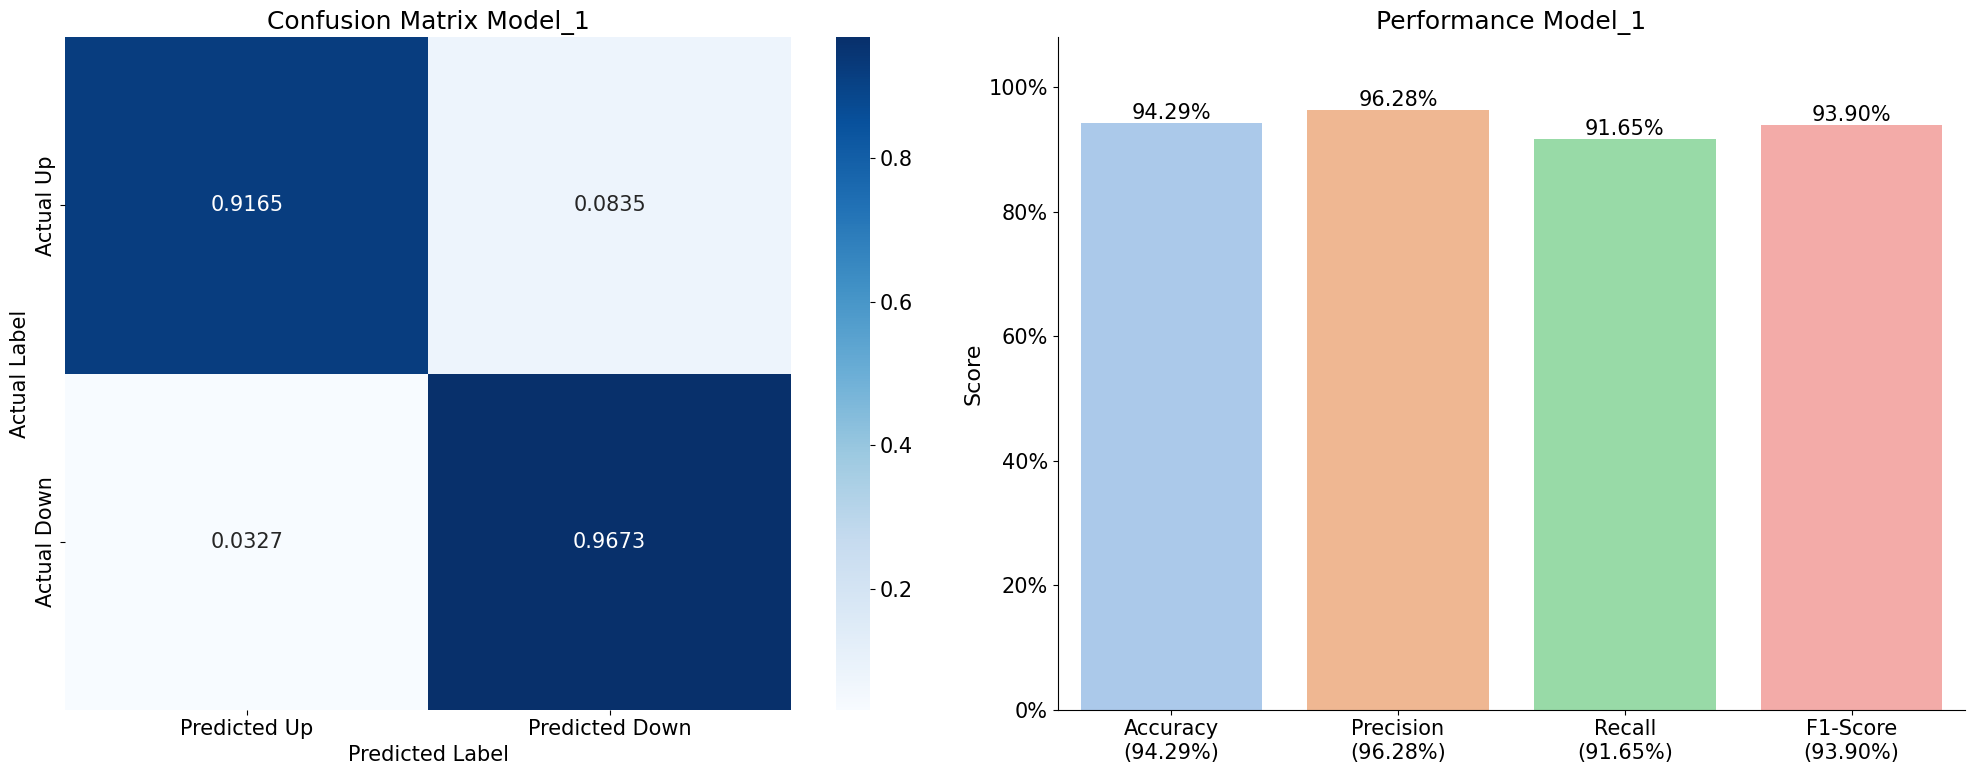

212/212 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step
Accuracy: 0.9368
Precision: 0.9855
Recall: 0.8813
F1-Score: 0.9305
[[0.88131936 0.11868064]
 [0.01194879 0.98805121]]


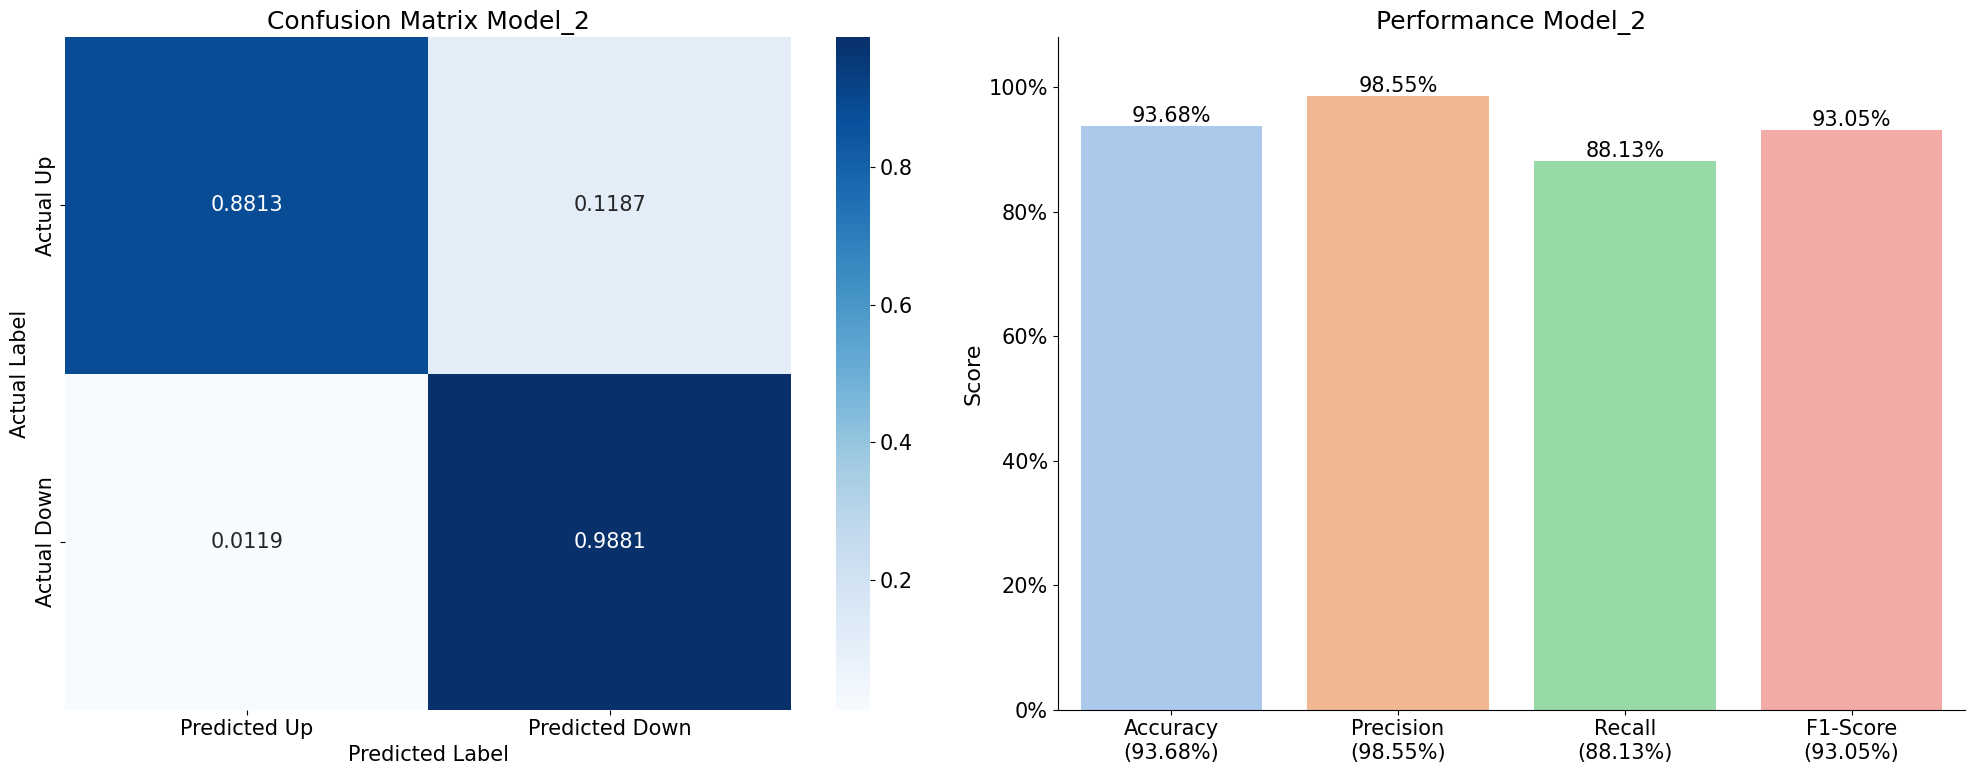

212/212 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step
Accuracy: 0.9547
Precision: 0.9791
Recall: 0.9254
F1-Score: 0.9515
[[0.92540074 0.07459926]
 [0.01820768 0.98179232]]


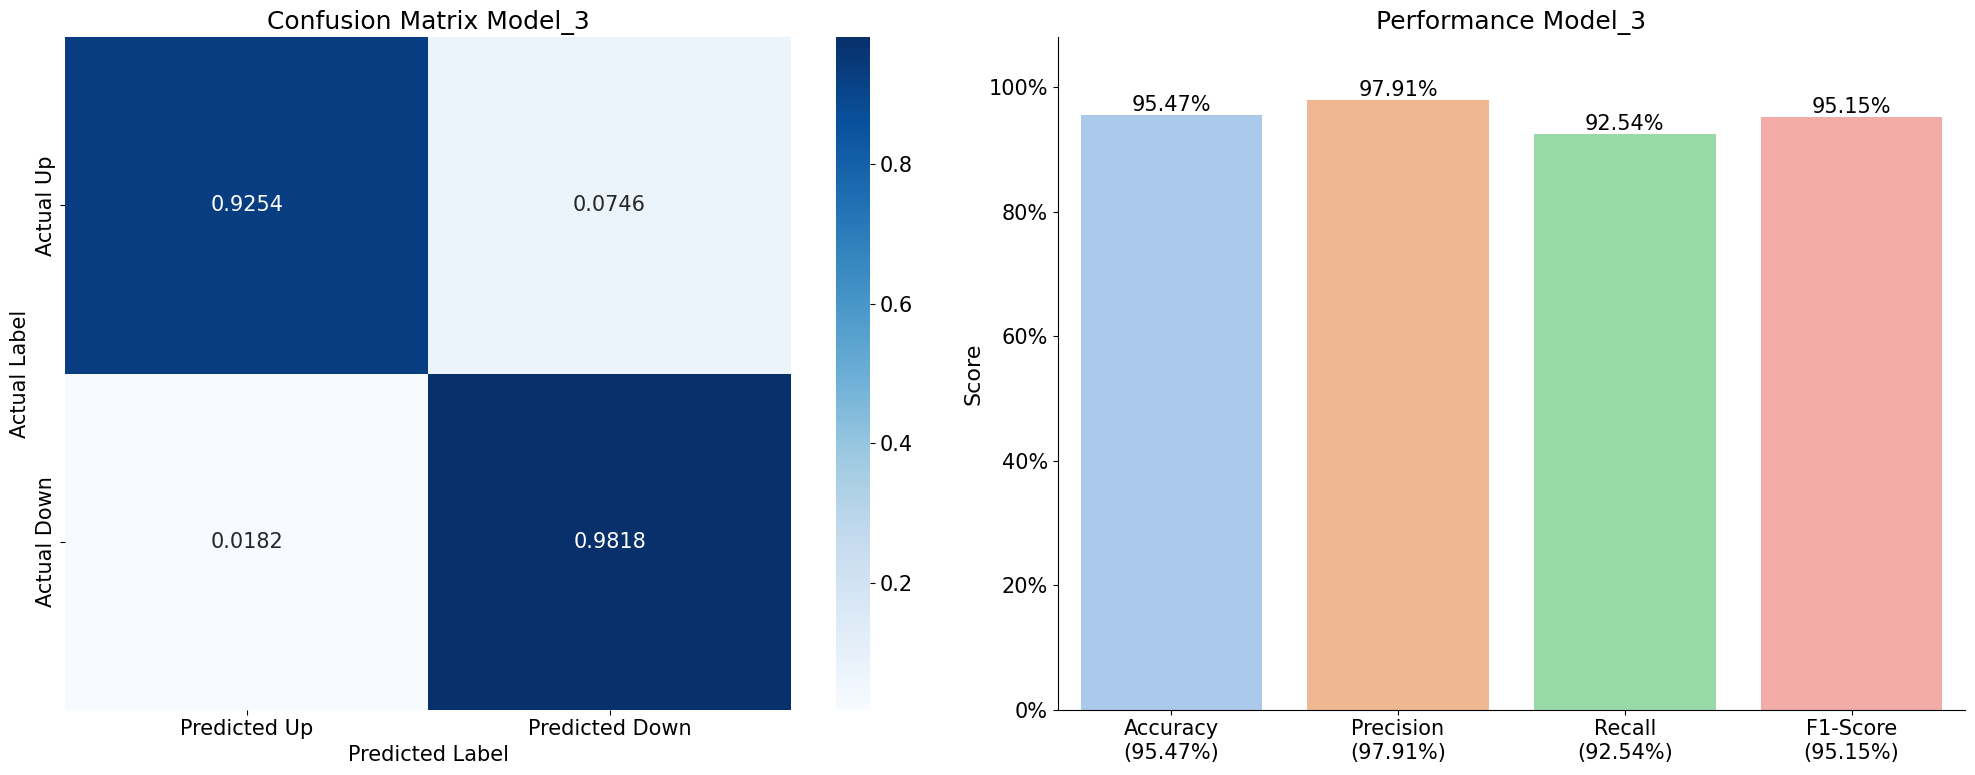

In [12]:
prediction1 = model_1.predict(X_validation)
matrix1 = getConfusionMatriks(prediction1,Y_validation)
plotConfusionMatrix(matrix1[0],matrix1[1],matrix1[2],matrix1[3],matrix1[4],title="Model_1")

prediction2 = model_2.predict(X_validation)
matrix2 = getConfusionMatriks(prediction2,Y_validation)
plotConfusionMatrix(matrix2[0],matrix2[1],matrix2[2],matrix2[3],matrix2[4],title="Model_2")

prediction3 = model_3.predict(X_validation)
matrix3 = getConfusionMatriks(prediction3,Y_validation)
plotConfusionMatrix(matrix3[0],matrix3[1],matrix3[2],matrix3[3],matrix3[4],title="Model_3")